# Annexes — Écosystème IA (Tout-en-un)

Ce notebook regroupe **toutes les annexes** demandées :
- Photos / schémas
- Code complet (watchdog + diagrammes)
- Exemple de sortie de simulation

## Annexe Photos / Schémas

### 1) Architecture matérielle
<img src="images/architecture.png" alt="Architecture matérielle" width="900"/>

### 2) Flux réseau
<img src="images/network_flow.png" alt="Flux réseau" width="900"/>

### 3) Pipeline CI/CD
<img src="images/cicd_pipeline.png" alt="Pipeline CI/CD" width="900"/>

## Annexe Code A — Watchdog complet
Script d'alerte thermique et d'erreurs ECC.

In [1]:
import time
import random

output_path = r"C:\Users\Public\Documents\TELECHARGEMENT\BdeB\scripts\watchdog_output.txt"

def watchdog_logger(temps, temp_gpu, errors_ecc):
    log = f"[LOG - Sec {temps}] Température GPU: {temp_gpu}°C | Erreurs ECC: {errors_ecc}\n"
    print(log, end='')
    with open(output_path, 'a', encoding='utf-8') as f:
        f.write(log)

    if temp_gpu > 82:
        alert = "  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!\n"
        print(alert, end='')
        with open(output_path, 'a', encoding='utf-8') as f:
            f.write(alert)

    if errors_ecc > 10:
        crit = "  --> [CRITICAL ERROR] Trop d'erreurs ECC ! Isolation du nœud et basculement du calcul.\n"
        print(crit, end='')
        with open(output_path, 'a', encoding='utf-8') as f:
            f.write(crit)
        return False

    return True

# Nettoyer le fichier de sortie
open(output_path, 'w', encoding='utf-8').close()

continuer_execution = True
for seconde in range(1, 11):
    if not continuer_execution:
        break
    temp_simulee = random.randint(70, 86)
    ecc_simulees = 0 if seconde < 6 else (seconde - 5) * 4
    continuer_execution = watchdog_logger(seconde, temp_simulee, ecc_simulees)
    time.sleep(1)

print(f"WROTE:{output_path}")

[LOG - Sec 1] Température GPU: 81°C | Erreurs ECC: 0
[LOG - Sec 2] Température GPU: 86°C | Erreurs ECC: 0
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 3] Température GPU: 85°C | Erreurs ECC: 0
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 4] Température GPU: 84°C | Erreurs ECC: 0
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 5] Température GPU: 86°C | Erreurs ECC: 0
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 6] Température GPU: 80°C | Erreurs ECC: 4
[LOG - Sec 7] Température GPU: 83°C | Erreurs ECC: 8
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 8] Température GPU: 78°C | Erreurs ECC: 12
  --> [CRITICAL ERROR] Trop d'erreurs ECC ! Isolation du nœud et basculement du calcul.
WROTE:C:\Users\Public\Documents\TELECHARGEMENT\BdeB\scripts\watchdo

## Annexe Code B — Génération du schéma d'architecture

WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/architecture.png


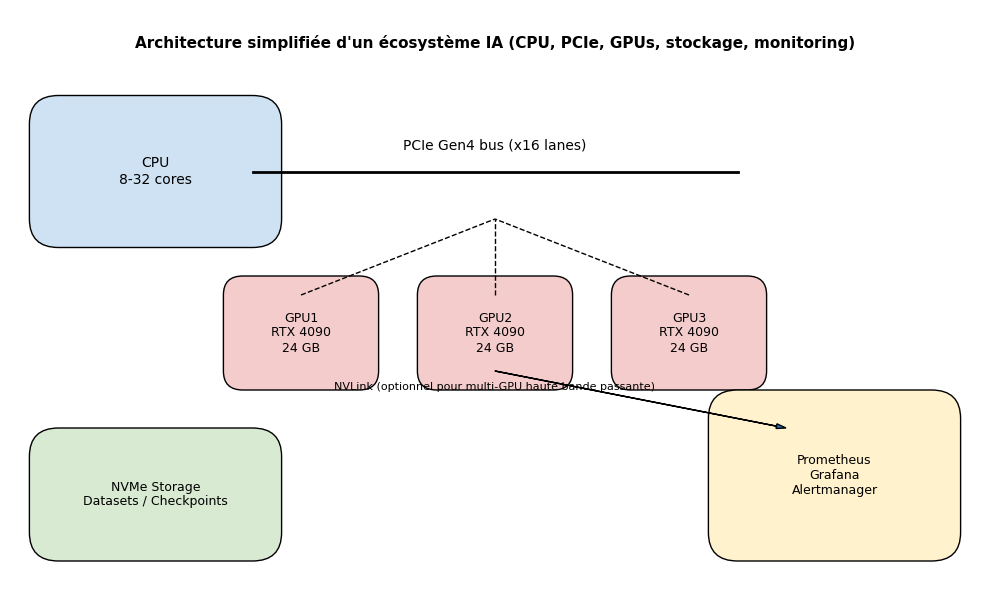

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10,6))
ax.set_xlim(0,10)
ax.set_ylim(0,6)
ax.axis('off')

# Draw CPU
cpu = patches.FancyBboxPatch((0.5,3.8),2,1,boxstyle='round,pad=0.3',edgecolor='black',facecolor='#cfe2f3')
ax.add_patch(cpu)
ax.text(1.5,4.3,'CPU\n8-32 cores',ha='center',va='center',fontsize=10)

# Draw PCIe bus
ax.plot([2.5,7.5],[4.3,4.3],color='black',linewidth=2)
ax.text(5,4.5,'PCIe Gen4 bus (x16 lanes)',ha='center',va='bottom')

# Draw GPUs
gpu_x = [3.0,5.0,7.0]
for i,x in enumerate(gpu_x):
    rect = patches.FancyBboxPatch((x-0.6,2.2),1.2,0.8,boxstyle='round,pad=0.2',edgecolor='black',facecolor='#f4cccc')
    ax.add_patch(rect)
    ax.text(x,2.6,f'GPU{i+1}\nRTX 4090\n24 GB',ha='center',va='center',fontsize=9)
    ax.plot([x,5.0],[3.0,3.8],color='black',linestyle='--',linewidth=1)

# NVLink annotation
ax.text(5,2.0,'NVLink (optionnel pour multi-GPU haute bande passante)',ha='center',fontsize=8)

# Storage
storage = patches.FancyBboxPatch((0.5,0.5),2,0.8,boxstyle='round,pad=0.3',edgecolor='black',facecolor='#d9ead3')
ax.add_patch(storage)
ax.text(1.5,0.9,'NVMe Storage\nDatasets / Checkpoints',ha='center',va='center',fontsize=9)

# Monitoring stack
prom = patches.FancyBboxPatch((7.5,0.5),2,1.2,boxstyle='round,pad=0.3',edgecolor='black',facecolor='#fff2cc')
ax.add_patch(prom)
ax.text(8.5,1.1,'Prometheus\nGrafana\nAlertmanager',ha='center',va='center',fontsize=9)
ax.arrow(5,2.2,3.0,-0.6,head_width=0.05,head_length=0.1,length_includes_head=True)

# Title
ax.text(5,5.6,"Architecture simplifiée d'un écosystème IA (CPU, PCIe, GPUs, stockage, monitoring)",ha='center',fontsize=11,weight='bold')

plt.tight_layout()
plt.savefig('c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/architecture.png',dpi=150)
print('WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/architecture.png')

## Annexe Code C — Génération du flux réseau

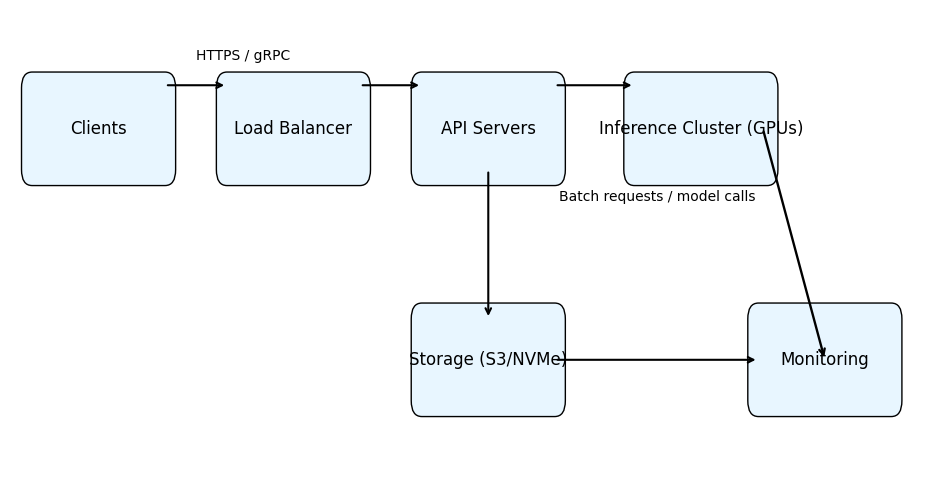

WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/network_flow.png


In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(12,6))
ax.set_xlim(0,10.5)
ax.set_ylim(0.4,3.9)
ax.axis('off')

# Nodes (positions ajustées)
nodes = {
    'Clients': (1.0,3.0),
    'Load Balancer': (3.2,3.0),
    'API Servers': (5.4,3.0),
    'Inference Cluster (GPUs)': (7.8,3.0),
    'Storage (S3/NVMe)': (5.4,1.25),
    'Monitoring': (9.2,1.25)
}

box_w, box_h = 1.5, 0.62
for name, (x, y) in nodes.items():
    rect = patches.FancyBboxPatch(
        (x - box_w / 2, y - box_h / 2), box_w, box_h,
        boxstyle='round,pad=0.12', edgecolor='black', facecolor='#e8f6ff'
    )
    ax.add_patch(rect)
    ax.text(x, y, name, ha='center', va='center', fontsize=12)

# Helpers
def arrow(a, b, lw=1.5):
    ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='->', lw=lw))

# Top horizontal flow arrows (placées au-dessus des boîtes)
top_y = 3.33
arrow((1.0 + box_w/2, top_y), (3.2 - box_w/2, top_y))
arrow((3.2 + box_w/2, top_y), (5.4 - box_w/2, top_y))
arrow((5.4 + box_w/2, top_y), (7.8 - box_w/2, top_y))

# Downstream arrows
arrow((5.4, 3.0 - box_h/2), (5.4, 1.25 + box_h/2))
arrow((7.8 + box_w/2 - 0.05, 3.0), (9.2, 1.25), lw=1.7)
arrow((5.4 + box_w/2, 1.25), (9.2 - box_w/2, 1.25))

# Labels
ax.text(2.1, 3.52, 'HTTPS / gRPC', fontsize=10)
ax.text(6.2, 2.45, 'Batch requests / model calls', fontsize=10)

plt.savefig('c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/network_flow.png', dpi=170, bbox_inches='tight', pad_inches=0.2)
plt.show()
print('WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/network_flow.png')

## Annexe Code D — Génération du pipeline CI/CD

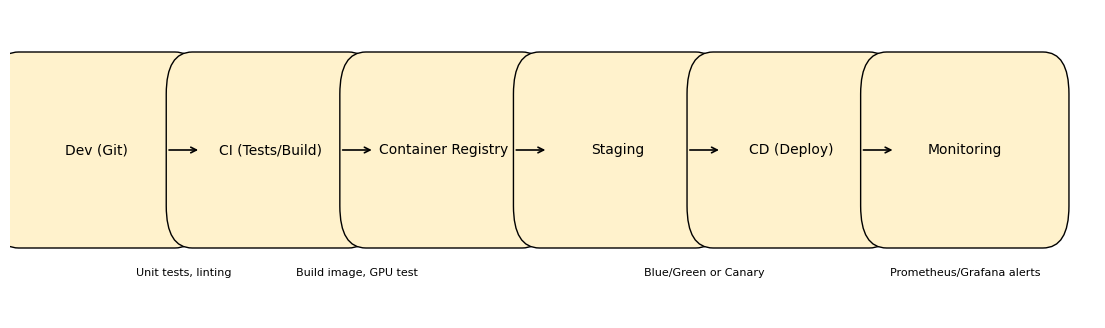

WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/cicd_pipeline.png


In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14,4))
ax.set_xlim(0,12.5)
ax.set_ylim(0.2,2.4)
ax.axis('off')

stages = ['Dev (Git)', 'CI (Tests/Build)', 'Container Registry', 'Staging', 'CD (Deploy)', 'Monitoring']
xs = [1,3,5,7,9,11]

for x,stage in zip(xs,stages):
    rect = patches.FancyBboxPatch((x-0.9,1.0),1.8,0.8,boxstyle='round,pad=0.3',edgecolor='black',facecolor='#fff2cc')
    ax.add_patch(rect)
    ax.text(x,1.4,stage,ha='center',va='center')

for i in range(len(xs)-1):
    ax.annotate('',xy=(xs[i+1]-0.8,1.4),xytext=(xs[i]+0.8,1.4),arrowprops=dict(arrowstyle='->',lw=1.2))

# annotations
ax.text(2,0.5,'Unit tests, linting',ha='center',fontsize=8)
ax.text(4,0.5,'Build image, GPU test',ha='center',fontsize=8)
ax.text(8,0.5,'Blue/Green or Canary',ha='center',fontsize=8)
ax.text(11,0.5,'Prometheus/Grafana alerts',ha='center',fontsize=8)

plt.savefig('c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/cicd_pipeline.png', dpi=160, bbox_inches='tight', pad_inches=0.2)
plt.show()
print('WROTE:c:/Users/Public/Documents/TELECHARGEMENT/BdeB/images/cicd_pipeline.png')

## Annexe Sortie — Simulation Watchdog
```text
[LOG - Sec 1] Température GPU: 71°C | Erreurs ECC: 0
[LOG - Sec 2] Température GPU: 81°C | Erreurs ECC: 0
[LOG - Sec 3] Température GPU: 79°C | Erreurs ECC: 0
[LOG - Sec 4] Température GPU: 85°C | Erreurs ECC: 0
  --> [ALERT SYSTEM] Vitesse d'horloge bridée automatiquement (Thermal Throttling)!
[LOG - Sec 5] Température GPU: 77°C | Erreurs ECC: 0
[LOG - Sec 6] Température GPU: 75°C | Erreurs ECC: 4
[LOG - Sec 7] Température GPU: 71°C | Erreurs ECC: 8
[LOG - Sec 8] Température GPU: 76°C | Erreurs ECC: 12
  --> [CRITICAL ERROR] Trop d'erreurs ECC ! Isolation du nœud et basculement du calcul.
```